In [1]:
import pandas as pd
import numpy as np
import math
from itertools import combinations
from collections import defaultdict
from pathlib import Path
from sklearn.neighbors import NearestNeighbors

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print(PROJECT_ROOT)
#Read the data
df = pd.read_parquet(PROCESSED_DIR / "recipes.parquet")
ingr = pd.read_parquet(PROCESSED_DIR / "ingredient_embeddings.parquet")

c:\Users\andre\OneDrive\Dokumente\Studium\Erasmus\02807 Computational tools for Data Science\Project\CDTGroup25


In [57]:
ingredients = ingr["ingredient"].tolist()
#ingredient_vectors = ingr["embedding"].tolist()
ingredient_vectors = np.array(ingr["embedding"].tolist(),dtype=np.float32)
threshold = 0.75
chunk_size = 256

matches = []

n = len(ingredients)

for start in range(0, n, chunk_size):
    end = min(start + chunk_size, n)

    # Compare this chunk against all ingredients
    similarities = (
        ingredient_vectors[start:end] @ ingredient_vectors.T
    )

    for local_i in range(end - start):
        i = start + local_i

        # Only consider pairs where i < j
        similarities[local_i, :i + 1] = -1

        indices = np.where(similarities[local_i] > threshold)[0]

        for j in indices:
            matches.append({
                "ingredient_1": ingredients[i],
                "ingredient_2": ingredients[j],
                "similarity": float(similarities[local_i, j])
            })

matches_df = pd.DataFrame(matches)

#matches_df.to_parquet("ingredient_candidates.parquet", index=False)

print(f"Found {len(matches_df)} candidate pairs")

Found 45928 candidate pairs


In [59]:
print(matches_df.tail(10))

                                   ingredient_1  \
45918             spinach and cheese tortellini   
45919       campbell's condensed vegetable soup   
45920                   chocolate cake doughnut   
45921            sugar-free chocolate ice cream   
45922           vanilla caramel truffle tea bag   
45923                       vegan sausage patty   
45924                     vegan chocolate syrup   
45925                vegetarian sausage crumble   
45926              vegetarian breakfast sausage   
45927  white chocolate cheesecake nonfat yogurt   

                                            ingredient_2  similarity  
45918                            tortellini cheese pasta    0.777004  
45919  campbell's half-fat condensed cream of mushroo...    0.767758  
45920                                  cinnamon doughnut    0.788685  
45921                     dairy free chocolate ice cream    0.861159  
45922                     vanilla flavored black tea bag    0.752752  
45923       

In [61]:
def token_jaccard(a, b):
    tokens_a = set(a.lower().split())
    tokens_b = set(b.lower().split())

    union = tokens_a | tokens_b

    if not union:
        return 1.0

    return len(tokens_a & tokens_b) / len(union)


def character_shingles(text, n):
    text = text.lower()
    text = " ".join(text.split())

    if len(text) < n:
        return {text}

    return {
        text[i:i+n]
        for i in range(len(text) - n + 1)
    }


In [63]:
def character_jaccard(a, b, n):
    shingles_a = character_shingles(a, n)
    shingles_b = character_shingles(b, n)

    union = shingles_a | shingles_b

    if not union:
        return 1.0

    return len(shingles_a & shingles_b) / len(union)


In [64]:
matches_df["token_jaccard"] = matches_df.apply(
    lambda row: token_jaccard(
        row["ingredient_1"],
        row["ingredient_2"]
    ),
    axis=1
)

matches_df["char_bigram"] = matches_df.apply(
    lambda row: character_jaccard(
        row["ingredient_1"],
        row["ingredient_2"],
        n=2
    ),
    axis=1
)

matches_df["char_trigram"] = matches_df.apply(
    lambda row: character_jaccard(
        row["ingredient_1"],
        row["ingredient_2"],
        n=3
    ),
    axis=1
)


In [72]:
matches_df = matches_df.sort_values(
    "token_jaccard",
    ascending=False
)

print(
    matches_df[
        [
            "ingredient_1",
            "ingredient_2",
            "similarity",
            "token_jaccard",
            "char_bigram",
            "char_trigram"
        ]
    ][10000:10010].to_string(index=False)
)


               ingredient_1                      ingredient_2  similarity  token_jaccard  char_bigram  char_trigram
  semisweet chocolate piece        semisweet baking chocolate    0.850567            0.5     0.580645      0.516129
                 sauerkraut                 canned sauerkraut    0.850577            0.5     0.533333      0.533333
         ranch dressing mix            low-fat ranch dressing    0.850627            0.5     0.520000      0.500000
vanilla instant pudding mix instant coconut cream pudding mix    0.850658            0.5     0.485714      0.410256
    baking chocolate square      bittersweet chocolate square    0.756086            0.5     0.500000      0.468750
         red cayenne pepper              fresh cayenne pepper    0.850714            0.5     0.700000      0.619048
 sugar-free cranberry juice       sugar-free cranberry jell-o    0.850717            0.5     0.700000      0.689655
                     fennel                       wild fennel    0.85071

In [78]:
filtered = matches_df[
    (matches_df["similarity"] <0.8) &
    (matches_df["token_jaccard"] < 0.50) &
    (matches_df["char_bigram"] < 0.50)
]

filtered = filtered.sort_values(
    "similarity",
    ascending=False
)

print(
    filtered[
        ["ingredient_1", "ingredient_2",
         "similarity", "token_jaccard",
         "char_bigram", "char_trigram"]
    ].to_string(index=False)
)
print(len(filtered))

                                                     ingredient_1                                                             ingredient_2  similarity  token_jaccard  char_bigram  char_trigram
                                                   coconut sorbet                                                        strawberry sorbet    0.799995       0.333333     0.285714      0.227273
                                                       mango pulp                                                              mango juice    0.799994       0.333333     0.357143      0.307692
                                                      salsa verde                                                              peach salsa    0.799982       0.333333     0.200000      0.200000
                                                      green olive                                                            italian olive    0.799973       0.333333     0.400000      0.333333
                                   

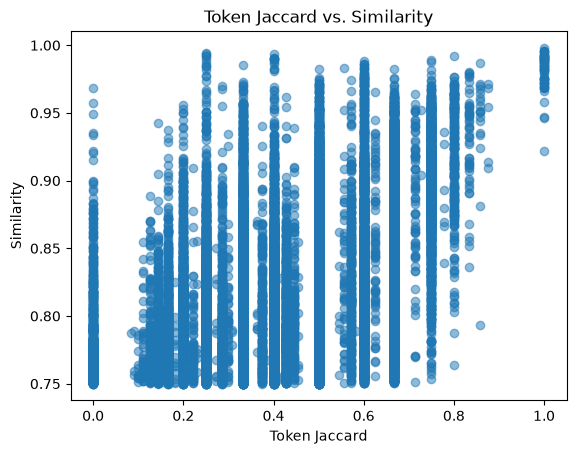

In [100]:
import matplotlib.pyplot as plt

plt.scatter(
    matches_df["token_jaccard"],
    matches_df["similarity"],
    alpha=0.5
)

plt.xlabel("Token Jaccard")
plt.ylabel("Similarity")
plt.title("Token Jaccard vs. Similarity")
plt.savefig("Similarity vs. Token Jaccard.png")
plt.show()

In [93]:
correlation = matches_df[
    ["similarity", "token_jaccard"]
].corr()

print(correlation)

               similarity  token_jaccard
similarity       1.000000       0.494446
token_jaccard    0.494446       1.000000


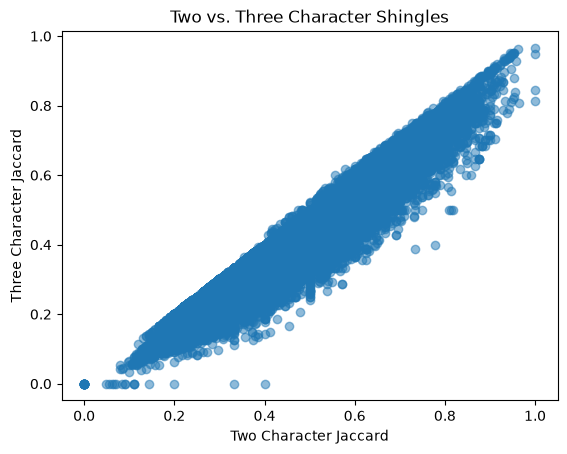

In [98]:
plt.scatter(
    matches_df["char_bigram"],
    matches_df["char_trigram"],
    alpha=0.5
)

plt.xlabel("Two Character Jaccard")
plt.ylabel("Three Character Jaccard")
plt.title("Two vs. Three Character Shingles")

plt.savefig("Two and three character shingles.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

In [99]:
correlation = matches_df[
    ["char_bigram", "char_trigram"]
].corr()

print(correlation)

              char_bigram  char_trigram
char_bigram       1.00000       0.95808
char_trigram      0.95808       1.00000


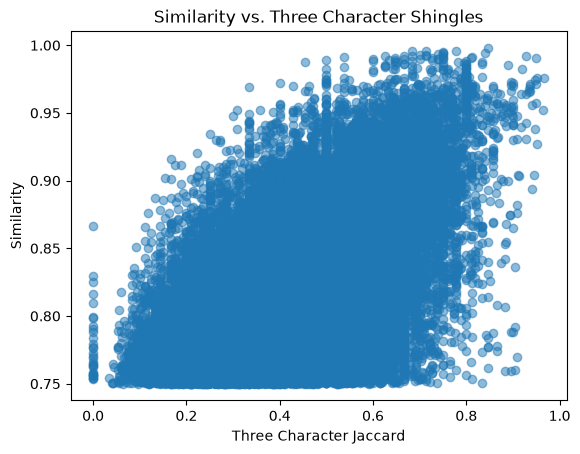

In [101]:
plt.scatter(
    matches_df["char_trigram"],
    matches_df["similarity"],
    alpha=0.5
)

plt.xlabel("Three Character Jaccard")
plt.ylabel("Similarity")
plt.title("Similarity vs. Three Character Shingles")
plt.savefig("Similarity vs. Three Character Shingles comparison.png")
plt.show()

In [102]:
correlation = matches_df[
    ["char_trigram","similarity"]
].corr()

print(correlation)

              char_trigram  similarity
char_trigram       1.00000     0.56353
similarity         0.56353     1.00000


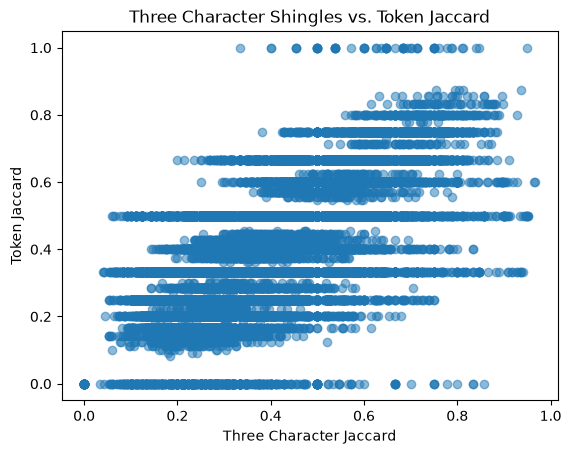

In [103]:
plt.scatter(
    matches_df["char_trigram"],
    matches_df["token_jaccard"],
    alpha=0.5
)

plt.xlabel("Three Character Jaccard")
plt.ylabel("Token Jaccard")
plt.title("Three Character Shingles vs. Token Jaccard")
plt.savefig("Word based vs. Three Character Shingles comparison.png")
plt.show()

In [104]:
correlation = matches_df[
    ["token_jaccard", "char_trigram"]
].corr()

print(correlation)

               token_jaccard  char_trigram
token_jaccard       1.000000      0.687389
char_trigram        0.687389      1.000000


In [105]:
print(len(matches_df))

45928


In [108]:
# Define cosine similarity ranges
bins = [0.75, 0.80, 0.85, 0.90, 0.95, 1.01]

# Assign each pair to a similarity range
matches_df["similarity_group"] = pd.cut(
    matches_df["similarity"],
    bins=bins,
    right=False
)

# Check how many pairs are available in each range
print(matches_df["similarity_group"].value_counts().sort_index())

# Select up to 40 pairs from each range
validation = (
    matches_df
    .groupby("similarity_group", observed=True, group_keys=False)
    .apply(lambda group: group.sample(
        n=min(40, len(group)),
        random_state=42
    ))
    .copy()
)

# Add an empty column for your manual labels
validation["merge_label"] = ""

# Save the validation dataset
validation.to_csv(
    "ingredient_validation.csv",
    index=False
)

similarity_group
[0.75, 0.8)     23962
[0.8, 0.85)     12534
[0.85, 0.9)      6332
[0.9, 0.95)      2552
[0.95, 1.01)      548
Name: count, dtype: int64


In [133]:
validation = pd.read_csv("ingredient_validation.csv")

validation["merge_label"] = pd.to_numeric(
    validation["merge_label"],
    errors="coerce"
)

validation = validation.dropna(
    subset=["merge_label"]
)

validation["merge_label"] = validation["merge_label"].astype(int)

In [134]:
print(validation.head())

                ingredient_1          ingredient_2  similarity  token_jaccard  \
0             canadian bacon         chicken bacon    0.781973       0.333333   
1  ready-to-serve beef broth  de-fatted beef broth    0.763426       0.500000   
2              yellow lentil         french lentil    0.764929       0.333333   
3               tomato juice                tomato    0.750805       0.500000   
4               chili pepper      vegetarian chili    0.750780       0.333333   

   char_bigram  char_trigram  merge_label  
0     0.333333      0.277778            0  
1     0.281250      0.281250            0  
2     0.352941      0.294118            1  
3     0.400000      0.400000            0  
4     0.190476      0.142857            0  


In [116]:
results = []

for cosine_threshold in [0.80, 0.85, 0.90, 0.93, 0.95, 0.97]:
    for token_threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
        for trigram_threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:

            predicted = (
                (validation["similarity"] >= cosine_threshold) &
                (validation["token_jaccard"] >= token_threshold) &
                (validation["char_trigram"] >= trigram_threshold)
            )

            actual = validation["merge_label"].astype(bool)

            true_positive = (predicted & actual).sum()
            false_positive = (predicted & ~actual).sum()
            false_negative = (~predicted & actual).sum()

            precision = (
                true_positive / (true_positive + false_positive)
                if true_positive + false_positive > 0 else 0
            )

            recall = (
                true_positive / (true_positive + false_negative)
                if true_positive + false_negative > 0 else 0
            )

            results.append({
                "cosine_threshold": cosine_threshold,
                "token_threshold": token_threshold,
                "trigram_threshold": trigram_threshold,
                "precision": precision,
                "recall": recall,
                "merges": int(predicted.sum())
            })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["merges", "precision", "recall"],
    ascending=[False, False, False]
)

print(results_df.head(20).to_string(index=False))


 cosine_threshold  token_threshold  trigram_threshold  precision   recall  merges
             0.80              0.3                0.3   0.611111 0.814815     144
             0.80              0.4                0.3   0.628788 0.768519     132
             0.80              0.3                0.4   0.613636 0.750000     132
             0.80              0.4                0.4   0.617886 0.703704     123
             0.80              0.5                0.3   0.614754 0.694444     122
             0.80              0.5                0.4   0.612069 0.657407     116
             0.85              0.3                0.3   0.672727 0.685185     110
             0.80              0.3                0.5   0.657407 0.657407     108
             0.85              0.3                0.4   0.676190 0.657407     105
             0.85              0.4                0.3   0.692308 0.666667     104
             0.80              0.4                0.5   0.660194 0.629630     103
             0.8

In [118]:
print(validation["merge_label"].value_counts())
total_positive = (validation["merge_label"] == 1).sum()

print("Total mergeable pairs:", total_positive)

merge_label
1    108
0     92
Name: count, dtype: int64
Total mergeable pairs: 108


In [119]:
bins = [0.75, 0.80, 0.85, 0.90, 0.95, 1.01]

matches_df["similarity_group"] = pd.cut(
    matches_df["similarity"],
    bins=bins,
    right=False
)

print(matches_df["similarity_group"].value_counts().sort_index())

similarity_group
[0.75, 0.8)     23962
[0.8, 0.85)     12534
[0.85, 0.9)      6332
[0.9, 0.95)      2552
[0.95, 1.01)      548
Name: count, dtype: int64


In [120]:
test_set = (
    matches_df
    .groupby("similarity_group", observed=True, group_keys=False)
    .apply(
        lambda group: group.sample(
            n=round(len(group) / len(matches_df) * 400),
            random_state=123
        )
    )
    .copy()
)

test_set["merge_label"] = ""

In [122]:
test_set.to_csv("ingredient_test_set.csv", index=False)

In [132]:
validation_test = pd.read_csv("ingredient_test_set.csv")

validation_test["merge_label"] = pd.to_numeric(
    validation_test["merge_label"],
    errors="coerce"
)

validation_test = validation_test.dropna(
    subset=["merge_label"]
)

validation_test["merge_label"] = validation_test["merge_label"].astype(int)

In [131]:
print(validation_test.info())
print(validation_test.head())

<class 'pandas.DataFrame'>
Index: 396 entries, 0 to 399
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ingredient_1   396 non-null    str    
 1   ingredient_2   396 non-null    str    
 2   similarity     396 non-null    float64
 3   token_jaccard  396 non-null    float64
 4   char_bigram    396 non-null    float64
 5   char_trigram   396 non-null    float64
 6   merge_label    396 non-null    int64  
dtypes: float64(4), int64(1), str(2)
memory usage: 39.9 KB
None
                            ingredient_1              ingredient_2  \
0                                   bean              vanilla bean   
1                 nonfat dry milk powder     nonfat protein powder   
2  macaroni and white cheddar cheese mix  simply macaroni & cheese   
3                fresh mozzarella cheese        buffalo mozzarella   
4                      marbled rye bread            rye breadcrumb   

   similarity  token_jaccard  c

In [159]:
test_results = []

for cosine_threshold in [0.80, 0.85, 0.90, 0.93, 0.95, 0.97]:
    for token_threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
        for trigram_threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
            
            
            predicted = (
                ((validation_test["similarity"] >= cosine_threshold) &
                (validation_test["token_jaccard"] >= token_threshold)) |
                ((validation_test["similarity"] >= cosine_threshold) &
                 (validation_test["char_trigram"] >= trigram_threshold)) #|
                #((validation_test["token_jaccard"] >= token_threshold) &
                # (validation_test["char_trigram"] >= trigram_threshold))
                
            )

            actual = validation_test["merge_label"].astype(bool)

            true_positive = (predicted & actual).sum()
            false_positive = (predicted & ~actual).sum()
            false_negative = (~predicted & actual).sum()

            precision = (
                true_positive / (true_positive + false_positive)
                if true_positive + false_positive > 0 else 0
            )

            recall = (
                true_positive / (true_positive + false_negative)
                if true_positive + false_negative > 0 else 0
            )

            test_results.append({
                "cosine_threshold": cosine_threshold,
                "token_threshold": token_threshold,
                "trigram_threshold": trigram_threshold,
                "precision": precision,
                "recall": recall,
                "merges": int(predicted.sum())
            })

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    ["merges", "precision", "recall"],
    ascending=[False, False, False]
)

print(test_results_df.head(20).to_string(index=False))


 cosine_threshold  token_threshold  trigram_threshold  precision   recall  merges
              0.8              0.3                0.3   0.441989 0.650407     181
              0.8              0.3                0.4   0.453488 0.634146     172
              0.8              0.4                0.3   0.441860 0.617886     172
              0.8              0.5                0.3   0.435294 0.601626     170
              0.8              0.3                0.5   0.455621 0.626016     169
              0.8              0.3                0.6   0.449102 0.609756     167
              0.8              0.3                0.7   0.449102 0.609756     167
              0.8              0.6                0.3   0.439759 0.593496     166
              0.8              0.7                0.3   0.439759 0.593496     166
              0.8              0.4                0.4   0.464968 0.593496     157
              0.8              0.5                0.4   0.466216 0.560976     148
              0.

In [162]:
test_results = []

for threshold in [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98]:
    predicted = validation_test["similarity"] >= threshold

    actual = validation_test["merge_label"].astype(bool)

    true_positive = (predicted & actual).sum()
    false_positive = (predicted & ~actual).sum()
    false_negative = (~predicted & actual).sum()

    precision = (
                true_positive / (true_positive + false_positive)
                if true_positive + false_positive > 0 else 0
            )

    recall = (
                true_positive / (true_positive + false_negative)
                if true_positive + false_negative > 0 else 0
            )

    test_results.append({
                "cosine_threshold": threshold,
                "token_threshold": "",
                "trigram_threshold": "",
                "precision": precision,
                "recall": recall,
                "merges": int(predicted.sum())
            })

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    ["merges", "precision", "recall"],
    ascending=[False, False, False]
)

print(test_results_df.head(20).to_string(index=False))


 cosine_threshold token_threshold trigram_threshold  precision   recall  merges
             0.80                                     0.436842 0.674797     190
             0.85                                     0.518519 0.341463      81
             0.90                                     0.538462 0.113821      26
             0.93                                     0.625000 0.040650       8
             0.95                                     0.750000 0.024390       4
             0.97                                     0.000000 0.000000       0
             0.98                                     0.000000 0.000000       0


In [163]:
test_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    predicted = validation_test["token_jaccard"] >= threshold

    actual = validation_test["merge_label"].astype(bool)

    true_positive = (predicted & actual).sum()
    false_positive = (predicted & ~actual).sum()
    false_negative = (~predicted & actual).sum()

    precision = (
                true_positive / (true_positive + false_positive)
                if true_positive + false_positive > 0 else 0
            )

    recall = (
                true_positive / (true_positive + false_negative)
                if true_positive + false_negative > 0 else 0
            )

    test_results.append({
                "cosine_threshold": "",
                "token_threshold": threshold,
                "trigram_threshold": "",
                "precision": precision,
                "recall": recall,
                "merges": int(predicted.sum())
            })

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    ["merges", "precision", "recall"],
    ascending=[False, False, False]
)

print(test_results_df.head(20).to_string(index=False))

cosine_threshold  token_threshold trigram_threshold  precision   recall  merges
                              0.3                     0.347541 0.861789     305
                              0.4                     0.385281 0.723577     231
                              0.5                     0.398907 0.593496     183
                              0.6                     0.555556 0.284553      63
                              0.7                     0.428571 0.024390       7
                              0.8                     0.000000 0.000000       0
                              0.9                     0.000000 0.000000       0


In [166]:
threshold = 0.95

predicted = validation_test["similarity"] >= threshold
actual = validation_test["merge_label"].astype(bool)

false_positives = validation_test[predicted & ~actual]

false_negatives = validation_test[~predicted & actual]

print("FALSE POSITIVES")

print(
    false_positives[
        ["ingredient_1", "ingredient_2", "similarity", "merge_label"]
    ].to_string(index=False)
)

print("\nFALSE NEGATIVES")

print(
    false_negatives[
        ["ingredient_1", "ingredient_2", "similarity", "merge_label"]
    ].to_string(index=False)
)

FALSE POSITIVES
   ingredient_1        ingredient_2  similarity  merge_label
whole grain oat whole grain oatmeal    0.965849            0

FALSE NEGATIVES
                                               ingredient_1                                    ingredient_2  similarity  merge_label
                                    fresh mozzarella cheese                              buffalo mozzarella    0.778753            1
                                           soft brown sugar                                brown sugar cube    0.769941            1
                                     lemon supreme cake mix              duncan hine lemon supreme cake mix    0.780368            1
                                                      pecan                                   roasted pecan    0.795603            1
                                    sweet whole kernel corn                          low-sodium kernel corn    0.781268            1
                                     dried red 

In [164]:
test_results = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    predicted = validation_test["char_trigram"] >= threshold

    actual = validation_test["merge_label"].astype(bool)

    true_positive = (predicted & actual).sum()
    false_positive = (predicted & ~actual).sum()
    false_negative = (~predicted & actual).sum()

    precision = (
                true_positive / (true_positive + false_positive)
                if true_positive + false_positive > 0 else 0
            )

    recall = (
                true_positive / (true_positive + false_negative)
                if true_positive + false_negative > 0 else 0
            )

    test_results.append({
                "cosine_threshold": "",
                "token_threshold": "",
                "trigram_threshold": threshold,
                "precision": precision,
                "recall": recall,
                "merges": int(predicted.sum())
            })

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    ["merges", "precision", "recall"],
    ascending=[False, False, False]
)

print(test_results_df.head(20).to_string(index=False))

cosine_threshold token_threshold  trigram_threshold  precision   recall  merges
                                                0.2   0.313673 0.951220     373
                                                0.3   0.341297 0.813008     293
                                                0.4   0.416216 0.626016     185
                                                0.5   0.526786 0.479675     112
                                                0.6   0.604651 0.211382      43
                                                0.7   0.684211 0.105691      19
                                                0.8   0.750000 0.024390       4


In [153]:
print(validation_test["merge_label"].value_counts())
total_positive = (validation_test["merge_label"] == 1).sum()

print("Total mergeable pairs:", total_positive)

merge_label
0    273
1    123
Name: count, dtype: int64
Total mergeable pairs: 123


In [156]:
good_rules = test_results_df[
    (test_results_df["precision"] >= 0.6) &
    (test_results_df["merges"] >= 50)
].sort_values(
    ["recall", "merges"],
    ascending=[False, False]
)

print(good_rules.head(20).to_string(index=False))

Empty DataFrame
Columns: [cosine_threshold, token_threshold, trigram_threshold, precision, recall, merges]
Index: []


In [117]:
good_rules = results_df[
    (results_df["precision"] >= 0.95) &
    (results_df["merges"] >= 10)
].sort_values(
    ["recall", "merges"],
    ascending=False
)

print(good_rules.head(20).to_string(index=False))

 cosine_threshold  token_threshold  trigram_threshold  precision   recall  merges
             0.93              0.3                0.7   0.965517 0.259259      29
             0.93              0.4                0.7   0.965517 0.259259      29
             0.93              0.5                0.7   0.964286 0.250000      28
             0.93              0.6                0.7   0.960000 0.222222      25
             0.93              0.7                0.3   0.956522 0.203704      23
             0.93              0.7                0.4   0.956522 0.203704      23
             0.93              0.7                0.5   0.956522 0.203704      23
             0.95              0.3                0.7   0.954545 0.194444      22
             0.95              0.4                0.7   0.954545 0.194444      22
             0.93              0.7                0.6   0.952381 0.185185      21
             0.95              0.5                0.7   0.952381 0.185185      21
             0.9

In [107]:
high_confidence = matches_df[
    (matches_df["similarity"] > 0.95) &
    (matches_df["token_jaccard"] > 0.60) &
    (matches_df["char_trigram"] > 0.60)
]
print(len(high_confidence))

266


In [7]:
#Get a quick overview of the dataset
print(df.info())

# Inspect a few ingredient lists
print(df["tags"].head())

<class 'pandas.DataFrame'>
Index: 228542 entries, 0 to 231636
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   name            228542 non-null  str    
 1   id              228542 non-null  int64  
 2   minutes         228542 non-null  int64  
 3   contributor_id  228542 non-null  int64  
 4   submitted       228542 non-null  str    
 5   tags            228542 non-null  object 
 6   n_steps         228542 non-null  int64  
 7   steps           228542 non-null  object 
 8   description     228542 non-null  str    
 9   ingredients     228542 non-null  object 
 10  n_ingredients   228542 non-null  int64  
 11  calories        228542 non-null  float64
 12  total_fat       228542 non-null  float64
 13  sugar           228542 non-null  float64
 14  sodium          228542 non-null  float64
 15  protein         228542 non-null  float64
 16  sat_fat         228542 non-null  float64
 17  carbs           228542 non

In [2]:
# Collect all unique ingredients
all_ingredients = set()

for ingredients in df["ingredients"]:
    all_ingredients.update(ingredients)

# Assign a stable integer ID to each ingredient
# First sort ingredients alphabetically to ensure consistent ordering
sorted_ingredients = sorted(all_ingredients)

ingredient_to_id = {
    ingredient: idx
    for idx, ingredient in enumerate(sorted_ingredients)
}

id_to_ingredient = {
    idx: ingredient
    for ingredient, idx in ingredient_to_id.items()
}

In [3]:
# Collect all unique tags
all_tags = set()

for tags in df["tags"]:
    all_tags.update(tags)

# Assign a stable integer ID to each tag
# First sort tags alphabetically to ensure consistent ordering
sorted_tags = sorted(all_tags)

tag_to_id = {
    tag: idx
    for idx, tag in enumerate(sorted_tags)
}

id_to_tag = {
    idx: tag
    for tag, idx in tag_to_id.items()
}

In [14]:
#Small check with one ingredient to see that id and ingredient match.
print("Unique ingredients:", len(ingredient_to_id))
print(ingredient_to_id["salt"])  # Example: Get the ID for "salt" get 11644
print(id_to_ingredient[11644])  # Example: Get the ingredient for ID 11644 get "salt"

Unique ingredients: 14801
11644
salt


In [15]:
baskets = []

for ingredients in df["ingredients"]:
    item_ids = {
        ingredient_to_id[item]
        for item in ingredients
    }
    baskets.append(sorted(item_ids))


In [9]:
baskets = []

for tags in df["tags"]:
    item_ids = {
        tag_to_id[tag]
        for tag in tags
    }
    baskets.append(sorted(item_ids))

In [16]:
#Small check if the mapping of the baskets is correct.
for id in baskets[0]:
    print(id_to_ingredient[id])  # Print the ingredient corresponding to each ID in the first basket
print(df["ingredients"].iloc[0])  # Print the original ingredient list for the first basket
#We see they coincide, so the mapping is correct.

butter
honey
mexican seasoning
mixed spice
olive oil
salt
winter squash
['winter squash' 'mexican seasoning' 'mixed spice' 'honey' 'butter'
 'olive oil' 'salt']


In [10]:
#We now start by setting up an array to count the number of occurrences of each ingredient across all baskets. 
#num_items = len(ingredient_to_id)
num_items = len(tag_to_id)

singleton_counts = np.zeros(num_items, dtype=np.int64)

for basket in baskets:
    for item_id in basket:
        singleton_counts[item_id] += 1

In [17]:
#Some statistics
print("Number of recipes:", len(baskets))
print("Number of unique ingredients:", num_items)

print(
    "Average ingredients per recipe:",
    np.mean([len(basket) for basket in baskets])
)

print(
    "Total ingredient occurrences:",
    singleton_counts.sum()
)

print(
    "Average occurrences per ingredient:",
    np.mean(singleton_counts)
)

Number of recipes: 228542
Number of unique ingredients: 552
Average ingredients per recipe: 9.051885430249145
Total ingredient occurrences: 4087383
Average occurrences per ingredient: 7404.679347826087


In [11]:
#Some statistics
print("Number of recipes:", len(baskets))
print("Number of unique tags:", num_items)

print(
    "Average tags per recipe:",
    np.mean([len(basket) for basket in baskets])
)

print(
    "Total tag occurrences:",
    singleton_counts.sum()
)

print(
    "Average occurrences per tag:",
    np.mean(singleton_counts)
)

Number of recipes: 228542
Number of unique tags: 552
Average tags per recipe: 17.884603267670713
Total tag occurrences: 4087383
Average occurrences per tag: 7404.679347826087


In [9]:
top_items = np.argsort(singleton_counts)[::-1][:20]

for item_id in top_items:
    ingredient = id_to_ingredient[item_id]
    count = singleton_counts[item_id]

    print(f"{ingredient}: {count}")

salt: 84627
butter: 54472
sugar: 43700
onion: 38644
water: 34245
eggs: 33405
olive oil: 32490
flour: 25987
milk: 25541
garlic cloves: 25475
pepper: 22066
brown sugar: 18372
garlic: 17673
all-purpose flour: 17478
baking powder: 17346
egg: 17148
salt and pepper: 15305
parmesan cheese: 14717
lemon juice: 13980
baking soda: 13968


In [20]:
#We recognize that some most common ingrediets are redundant, e.g. "salt" and "salt and pepper".
#Hence let us do a short check to see how many such edge cases we have.
# Search for ingredient descriptions containing "and"
and_ingredients = [
    ingredient
    for ingredient in all_ingredients
    if " and " in ingredient.lower()
]

print("Number of descriptions containing 'and':", len(and_ingredients))
for ingredient in and_ingredients:
    print(ingredient)

Number of descriptions containing 'and': 357
frozen mixed potatoes carrots celery and onions
lemon, juice and zest of
mushroom and garlic couscous
crunchy sweetened corn and oat cereal
frozen peas and carrot
stewed tomatoes with peppers and celery
kraft tuscan house italian dressing and marinade
ragu parmesan and romano spaghetti sauce
sour cream and onion potato chips
lipton beef-flavor noodles and sauce
fruit and bran cereal
cheddar and american blend cheese
good seasons garlic and herb seasoning mix
maple and brown sugar flavored hot wheat cereal mix
diced tomatoes with lime and cilantro
diced tomatoes with basil oregano and garlic
vegan sweet and sour sauce
tomato sauce with basil garlic and oregano
cabbage and carrot coleslaw mix
split pea and ham soup
shredded steak and cheese taquitos
mrs. dash garlic and herb seasoning
onion and garlic croutons
lime, juice and zest of
chocolate flavor instant pudding and pie filling mix
greek vinaigrette dressing with feta and oregano
cream che

In [21]:
for keyword in ["salt", "pepper", "garlic", "egg", "flour", "rice", "sugar", "butter", "milk", "onion"]:
    print(f"\n--- {keyword.upper()} ---")

    matches = [
        ingredient
        for ingredient in all_ingredients
        if keyword in ingredient.lower()
    ]

    for ingredient in sorted(matches):
        print(ingredient)



--- SALT ---
aunt jane's krazy mixed up salt
black salt
butter-flavored salt
canned salt-reduced spaghetti
canning salt
capers packed in salt
cavenders salt-free all purpose greek seasoning
celery salt
chex mix sweet and salty trail mix
chicken salt
chinese salt
coarse salt
coarse sea salt
crazy salt
curing salt
dried salt cod fish
dry roasted salted peanut
dry roasted salted peanuts
dry-roasted salted macadamia nuts
dry-roasted salted mixed nuts
dry-roasted unsalted peanuts
epsom salts
fat salt pork
fat-free saltine crackers
fine salt
fine sea salt
flaked sea salt
fruit salt
garlic salt
garlic salt with parsley
garlic sea salt
gray salt
hawaiian sea salt
herb-seasoned salt
herbal salt substitute
herbamare herb seasoning salt
hickory smoke salt
hot salt
hunt's no-salt-added tomato paste
hunt's tomato sauce-no salt added
iodized salt
j&d peppered bacon salt
jalapeno seasoning salt
kosher salt
kosher salt & freshly ground black pepper
lactose-free unsalted margarine
large capers packed 

Although we have to deal with this issues we first implement the framework for the PCY-algorithm and come back later - if one get unreasonable results - to this issue.

In [27]:
from nltk.stem import WordNetLemmatizer
import nltk
import re
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()

lemmatizer = WordNetLemmatizer()

def normalize_ingredient(ingredient):
    ingredient = ingredient.lower().strip()
    ingredient = re.sub(r"\s+", " ", ingredient)

    words = ingredient.split()

    normalized_words = [
        lemmatizer.lemmatize(word, pos="n")
        for word in words
    ]

    return " ".join(normalized_words)


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\andre\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [28]:
print(normalize_ingredient(" yellow sweet onions"))  # Output: "tomato"

yellow sweet onion


In [11]:
#We use as starting parameters for the PCY algorithm the following thresholds:
min_support = 1000  # Minimum number of occurrences for an ingredient to be considered frequent
num_buckets = 100000  # Number of buckets for hashing pairs of ingredients (can be increased)
#Additionally we need a hash-function to map pairs of ingredients to buckets.
def hash_pair(i, j):
    return hash((min(i, j), max(i, j))) % num_buckets

In [12]:
# We redo the counting of singletons to have it all in one cell
# Count occurrences of individual ingredients
singleton_counts = np.zeros(num_items, dtype=np.int64)

# Count occurrences of hashed ingredient pairs
bucket_counts = np.zeros(num_buckets, dtype=np.int64)

for basket in baskets:

    # Count individual ingredients
    for item in basket:
        singleton_counts[item] += 1

    # Hash every pair into a bucket
    for item1, item2 in combinations(basket, 2):
        bucket = hash_pair(item1, item2)
        bucket_counts[bucket] += 1

In [13]:
print("Total singleton occurrences:", singleton_counts.sum())
print("Total pair occurrences:", bucket_counts.sum())

print("Number of non-empty buckets:", np.count_nonzero(bucket_counts))
print("Maximum bucket count:", bucket_counts.max())
print("Average bucket count:", bucket_counts.mean())

Total singleton occurrences: 2068736
Total pair occurrences: 9917661
Number of non-empty buckets: 100000
Maximum bucket count: 25390
Average bucket count: 99.17661


In [ ]:
# Create the PCY bitmap
frequent_buckets = bucket_counts >= min_support

print("Number of frequent buckets:", np.count_nonzero(frequent_buckets))
print("Number of infrequent buckets:", np.count_nonzero(~frequent_buckets))

# Identify frequent individual ingredients
frequent_items = singleton_counts >= min_support

print("Number of frequent individual ingredients:",
      np.count_nonzero(frequent_items))

Number of frequent buckets: 824
Number of infrequent buckets: 99176
Number of frequent individual ingredients: 315


In [17]:
pair_counts = defaultdict(int)

for basket in baskets:

    # Keep only frequent individual ingredients
    frequent_basket = [
        item for item in basket
        if frequent_items[item]
    ]

    # Generate pairs from the remaining ingredients
    for i, j in combinations(frequent_basket, 2):

        bucket = hash_pair(i, j)

        # Only count pairs hashing to frequent buckets
        if frequent_buckets[bucket]:
            pair_counts[(i, j)] += 1

In [18]:
frequent_pairs = {
    pair: count
    for pair, count in pair_counts.items()
    if count >= min_support
}

print("Number of candidate pairs counted:", len(pair_counts))
print("Number of frequent pairs:", len(frequent_pairs))

Number of candidate pairs counted: 1259
Number of frequent pairs: 735


In [22]:
top_pairs = sorted(
    frequent_pairs.items(),
    key=lambda x: x[1],
    reverse=True
)[:20]

for (i, j), count in top_pairs:
    print(
        f"{id_to_ingredient[i]} + {id_to_ingredient[j]}: {count}"
    )

butter + salt: 25335
salt + sugar: 22362
eggs + salt: 17928
pepper + salt: 17392
onion + salt: 16437
flour + salt: 16235
salt + water: 15170
butter + sugar: 14885
butter + eggs: 14071
butter + flour: 13720
olive oil + salt: 13194
baking powder + salt: 13115
eggs + sugar: 12808
milk + salt: 12751
all-purpose flour + salt: 12090
butter + milk: 11598
flour + sugar: 11006
baking soda + salt: 10672
garlic cloves + salt: 10492
egg + salt: 9709


In [23]:
# Set of all frequent pairs
frequent_pair_set = set(frequent_pairs.keys())

# Group pairs by their first ingredient
pairs_by_first = defaultdict(list)

for i, j in frequent_pair_set:
    pairs_by_first[i].append(j)

# Generate candidate triples
candidate_triples = set()

for i, items in pairs_by_first.items():

    items = sorted(items)

    for j, k in combinations(items, 2):

        # Check whether the third pair is also frequent
        if (j, k) in frequent_pair_set:
            candidate_triples.add((i, j, k))

print("Number of candidate triples:", len(candidate_triples))

Number of candidate triples: 2404


In [24]:
triple_counts = defaultdict(int)

for basket in baskets:

    # Keep only frequent individual ingredients
    frequent_basket = [
        item for item in basket
        if frequent_items[item]
    ]

    # Generate all triples in this recipe
    for triple in combinations(frequent_basket, 3):

        # Count only candidate triples
        if triple in candidate_triples:
            triple_counts[triple] += 1

In [25]:
frequent_triples = {
    triple: count
    for triple, count in triple_counts.items()
    if count >= min_support
}

print("Number of candidate triples:", len(candidate_triples))
print("Number of frequent triples:", len(frequent_triples))

Number of candidate triples: 2404
Number of frequent triples: 518


In [26]:
top_triples = sorted(
    frequent_triples.items(),
    key=lambda x: x[1],
    reverse=True
)[:20]

for (i, j, k), count in top_triples:
    ingredients = [
        id_to_ingredient[i],
        id_to_ingredient[j],
        id_to_ingredient[k]
    ]

    print(f"{ingredients}: {count}")

['butter', 'salt', 'sugar']: 8718
['butter', 'flour', 'salt']: 8364
['eggs', 'salt', 'sugar']: 8092
['butter', 'eggs', 'salt']: 8042
['flour', 'salt', 'sugar']: 7765
['baking powder', 'salt', 'sugar']: 7233
['butter', 'milk', 'salt']: 6713
['butter', 'eggs', 'sugar']: 6710
['baking powder', 'eggs', 'salt']: 6489
['onion', 'pepper', 'salt']: 6200
['butter', 'flour', 'sugar']: 6180
['eggs', 'flour', 'salt']: 6176
['baking powder', 'butter', 'salt']: 5843
['baking soda', 'eggs', 'salt']: 5730
['baking soda', 'salt', 'sugar']: 5681
['baking powder', 'flour', 'salt']: 5633
['eggs', 'flour', 'sugar']: 5379
['all-purpose flour', 'butter', 'salt']: 5377
['baking powder', 'baking soda', 'salt']: 5293
['milk', 'salt', 'sugar']: 5188
